# LSTM vs Transformer

### Configuración del entorno

In [46]:
!pip install -q evaluate rouge_score datasets transformers

In [47]:
import time, math, random, json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

#pongo semillas para asegurar reproducibilidad
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)
if device.type == "cpu":
    print("AVISO: sin GPU el entrenamiento será mucho más lento. Activa una GPU en Colab.")

# para guardar los resultados para el informe
RESULTS = {}

Dispositivo: cuda


In [48]:
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


### Parte A: Modelo LSTM para generación de texto secuencial

In [49]:
#descargando el texto
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
#esta abriendo una conexion http a la direccion del url
text = urllib.request.urlopen(URL).read().decode("utf-8")
print("Total de caracteres:", len(text))
print(text[:300])

Total de caracteres: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [50]:
#se convierten el texto en numeros
#set(text) - toma todos los caracteres del texto y
#deja solo los valores unicos (sin repetir)
#la funcion sorted() los ordena y devuelve una lista
chars = sorted(set(text))

#guarda la cantidad de caracteres distintos que existen
vocab_size = len(chars)

#crea un diccionario string to integer
stoi = {}

for index, char in enumerate(chars):
    stoi[char] = index
print(stoi)

#con esto se traduce a vueltas legibles
#es un diccionario inversion integer to string
itos = {}
#stoi.items() devuelve los pares del diccionario como tuplas
# [('\n', 0), ('', 1), ('!', 2), ...]
for char, index in stoi.items():
    itos[index] = char
print(itos)
#este for loop toma cada par caracter: numero y
#lo voltea numero: caracter.

#convertimos el texto completo en una lista de
#numeros
#cada caracter se reemplaza por su numero segun
#el diccioario stoi
numeros = []
for caracter in text:
    numero = stoi[caracter]
    numeros.append(numero)

print(numeros)

{'\n': 0, ' ': 1, '!': 2, '$': 3, '&': 4, "'": 5, ',': 6, '-': 7, '.': 8, '3': 9, ':': 10, ';': 11, '?': 12, 'A': 13, 'B': 14, 'C': 15, 'D': 16, 'E': 17, 'F': 18, 'G': 19, 'H': 20, 'I': 21, 'J': 22, 'K': 23, 'L': 24, 'M': 25, 'N': 26, 'O': 27, 'P': 28, 'Q': 29, 'R': 30, 'S': 31, 'T': 32, 'U': 33, 'V': 34, 'W': 35, 'X': 36, 'Y': 37, 'Z': 38, 'a': 39, 'b': 40, 'c': 41, 'd': 42, 'e': 43, 'f': 44, 'g': 45, 'h': 46, 'i': 47, 'j': 48, 'k': 49, 'l': 50, 'm': 51, 'n': 52, 'o': 53, 'p': 54, 'q': 55, 'r': 56, 's': 57, 't': 58, 'u': 59, 'v': 60, 'w': 61, 'x': 62, 'y': 63, 'z': 64}
{0: '\n', 1: ' ', 2: '!', 3: '$', 4: '&', 5: "'", 6: ',', 7: '-', 8: '.', 9: '3', 10: ':', 11: ';', 12: '?', 13: 'A', 14: 'B', 15: 'C', 16: 'D', 17: 'E', 18: 'F', 19: 'G', 20: 'H', 21: 'I', 22: 'J', 23: 'K', 24: 'L', 25: 'M', 26: 'N', 27: 'O', 28: 'P', 29: 'Q', 30: 'R', 31: 'S', 32: 'T', 33: 'U', 34: 'V', 35: 'W', 36: 'X', 37: 'Y', 38: 'Z', 39: 'a', 40: 'b', 41: 'c', 42: 'd', 43: 'e', 44: 'f', 45: 'g', 46: 'h', 47: 'i',

In [51]:
#convertimos la lista de numeros en un tensor de PyTorch
#dtype=torch.long significa "enteros", que es lo que neesita la capa Embedding
data = torch.tensor(numeros, dtype=torch.long)

#muestra los primeros 20 numeros
print(data[:20])

#muestra cuantos numeros hay en total
print(data.shape)

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56])
torch.Size([1115394])


In [52]:
#particion 90 % / 10 % respetando el orden del texto
#no voy a revolver el texto antes de dividirlo para
#evitar fuga de datos
n_train = int(0.9*len(data))
train_data = data[: n_train]
val_data = data[n_train:]
print(f"Tamaño del vocabulario: {vocab_size} | entrenamiento: {len(train_data):,} | validación: {len(val_data):,}")

Tamaño del vocabulario: 65 | entrenamiento: 1,003,854 | validación: 111,540


In [53]:
#longitud de contexto (caracteres)
SEQ_LEN = 100

#tamaño de lote
BATCH   = 128

La siguiente funcion crea un lote (batch) de ejemplos para entrenar o validar. Cada ejemplo es una ventana de SEQ_LEN caracteres (100 caracteres) seguidos:
    - x: la ventana de entrada
    - y: la misma ventana movida un caracter a la derecha (lo que el modelo debe de predecir)

Ejemplo: con ventanas de 5 caracteres, texto "Hello world":
    x = "Hello" -> y = "ello"

In [54]:
def get_batch(split):
    #aqui elijo que parte del texto tomo las ventanas
    if split == "train":
        source_data = train_data
    else:
        source_data = val_data

    #elijo al azar donde empieza cada ventana
    #el limite superior baja espacio para que
    #la ventana y su desplazamiento no se
    #salgan del texto
    max_start = len(source_data) - SEQ_LEN - 1
    start_positions = torch.randint(0, max_start, (BATCH,))

    #recortar las ventanas de entrada(x) y las de salida esperada (y)
    x_windows = []
    y_windows = []

    for start in start_positions:

        #convertir tensor a numero normal
        start = start.item()

        #caracteres de la posicion start en adelante
        x_window = source_data[start : start + SEQ_LEN]

        #igual, pero desplazada 1 caracter
        y_window = source_data[start + 1 : start + SEQ_LEN + 1]

        x_windows.append(x_window)
        y_windows.append(y_window)

        #apilas todas las ventanas en un solo tesnor de forma (BATCH, SEQ_LEN)
    x = torch.stack(x_windows)
    y = torch.stack(y_windows)

    #mandar los tensores al GPU o CPU donde vive el modelo
    return x.to(device), y.to(device)

#probamos la funcion con un lote de entrenamiento
x_batch, y_batch = get_batch("train")

#esperado: (128, 100) y (128, 100)
print("Forma de un lote:", x_batch.shape, y_batch.shape)

Forma de un lote: torch.Size([128, 100]) torch.Size([128, 100])


Arquitectura y configuración del modelo

*   Embedding (128): convierte cada caracter en un vector denso
*   LSTM de 2 capas (256 unidades ocultas, dropout 0.3 entre capas): cada celda usa compuertas de olvido, entrada y salida para decidir qué información conservar, lo que mitiga el desvanecimiento del gradiente de una RNN simple.
*   Capa lineal (logits): se entrena con entropia cruzada
*   Optimizador Adam (lr = 2e-3) y recorte de gradiente (clip_grad_norm_ = 1.0) para evitar la explosión del gradiente.



Modelo que predice el siguiente caracter a partir de los anteriores.

Flujo de datos:
    numeros (caracteres) -> embedding -> LSTM -> dropout -> capa lineal -> puntuaciones

la funcion forward:

x: tensor de numeros de caracter, forma (lote, tiempo), por ejemplo (128, 100)
state: memoria de la LSTM de la llamada anterior (None = empezar desde cero)

In [55]:
class CharLSTM(nn.Module):

    def __init__(self, vocab_size, embedding_size=128, hidden_size=256, num_layers=2, dropout_rate=0.3):
        #incializa la parte "base" de PyTorch
        #es obligatorio
        super().__init__()

        #Embedding: convierte cada numero de caracter en un vector de 128 valores
        #es una tabla de busqueda: 65 filas (una por caracter) x 128 columnas
        self.embedding = nn.Embedding(vocab_size, embedding_size)

        #LSTM: lee la secuencia de vectores y construye una "memoria" del contexto
        # -num_layers=2: dos LSTM apiladas (la salida de la primera entra a la segunda)
        # -batch_first=True: los datos llegan con forma (lote, tiempo, valores)
        # -dropout: apaga neuronas al azar ENTRE las dos capas para evitar sobreajuste
        #La primera capa de LSTM lee los vectores de los caracteres y produce una
        #secuencia de estados ocultos. La segunda capa toma esa secuencia como entrada
        #y la procesa otra vez.
        self.lstm = nn.LSTM(
            input_size = embedding_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_rate
        )

        #dropout apaga el 30% de los valores al azar justo antes de la capa final.
        #solamente actua durante el entrenamiento (model.train()), no al evaluar
        #o generar texto
        self.dropout = nn.Dropout(dropout_rate)

        #la capa lineal convierte los 256 valores de la LSTM en 65 puntuaciones,
        #una por cada caracter posible del vocabulario
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, state=None):
        #paso 1: numeros -> vectores. (128, 100) -> (128, 100, 128)
        vectors = self.embedding(x)

        #paso 2: la LSTM procesa la secuencia (128, 100, 128) -> (128, 100, 256)
        #tambien devuelve su memoria actualizada (state) para poder continuar
        #despues
        lstm_output, state = self.lstm(vectors, state)

        #paso 3: dropout (solo en entrenamiento)
        lstm_output = self.dropout(lstm_output)

        #paso 4: puntuaciones (logits) para cada caracter posible
        logits = self.output_layer(lstm_output)

        return logits, state

In [56]:
#crear el modelo y enviarlo al GPU (CPU)
lstm_model = CharLSTM(vocab_size).to(device)

In [57]:
#contar parametros: se recorre cada tensor de pesos del modelo y
#y se suman sus elementos
lstm_params = 0
for parameter in lstm_model.parameters():
    #numel() = numero de elementos del tensor
    lstm_params += parameter.numel()

print(lstm_model)
print(f"Parámetros del LSTM: {lstm_params:,}")

CharLSTM(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (output_layer): Linear(in_features=256, out_features=65, bias=True)
)
Parámetros del LSTM: 946,625


Entrenamiento

Cada EVAL_EVERY voy a medir la funcion de pérdida.

In [58]:
#configuracion del entrenamiento

#cuantas veces vamos a actualizar el modelo
STEPS = 3000

#cada cuantos pasos medimos el desempeño de validación
EVAL_EVERY = 250

#tasa de aprendizaje
TASA_APRENDIZAJE = 0.002

#optimizador: el que ajsuta los pesos de modelo usando los gradientes
optimizer = torch.optim.Adam(lstm_model.parameters(), lr = TASA_APRENDIZAJE)

#funcion de perdida: mide que tan equivocadas estan las predicciones
loss_fn = nn.CrossEntropyLoss()

In [59]:
#funcion para evaluar en validacion

#esto indica que no se debe calcular el gradiente aqui
#solamente medimos, no entrenamos para que sea mas rapido
@torch.no_grad()

def evaluate_lstm(n_batches = 20):

    #apaga el dropout para medir el modelo "completo"
    lstm_model.eval()

    all_losses = []
    all_accuracies = []

    for _ in range(n_batches):
        x, y = get_batch("val")

        #logits: (128, 100, 65)
        logits, _ = lstm_model(x)

        #la perdida espera una tabla 2D (todas las posiciones, 65 puntuaciones)
        #y los objetivos como una lista 1D

        #(12800, 65)
        logits_2d = logits.reshape(-1, vocab_size)

        #(12900,)
        targets_1d = y.reshape(-1)

        loss = loss_fn(logits_2d, targets_1d)

        all_losses.append(loss.item())

        #exactitud
        predicted_chars = logits.argmax(dim=-1)
        accuracy = (predicted_chars == y).float().mean().item()
        all_accuracies.append(accuracy)

    #reactivar el dropout para seguir entrenando
    lstm_model.train()

    average_loss = float(np.mean(all_losses))
    average_accuracy = float(np.mean(all_accuracies))

    return average_loss, average_accuracy

In [60]:
#preparar el registro de resultados

history = {"step": [], "train_loss": [], "val_loss":[], "val_acc":[]}

#acumula la perdida de entrenamiento entre evaluaciones
running_loss = 0.0

#en el GPU las operaciones son asincronas,
#tenemos que sincronizar para que el cronometro
#sea exacto
if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.time()

In [61]:
#ciclo de entrenamiento

#modo entrenamiento (dropout activo)
lstm_model.train()

for step in range(1, STEPS + 1):

    #1 obtener un lote de ejemplos de entrenamiento
    x, y = get_batch("train")

    #2 forward pass: el modelo hace sus predicciones
    logits, _ = lstm_model(x)

    #3 mide el error de esas predicciones
    loss = loss_fn(logits.reshape(-1, vocab_size), y.reshape(-1))

    #4 borrar los gradientes del paso anterior (si no se borran, se acumulan)
    optimizer.zero_grad()

    #5 backpropagation para calcular cada peso
    loss.backward()

    #6 recortar gradientes demasiado grandes para evitar que exploten
    nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)

    #7 se actualizan los pesos usando los gradientes y la tasa de aprendizaje
    optimizer.step()

    running_loss += loss.item()

    #cada EVAL_EVERY pasos: evaluar, guardar y mostrar resultados
    if step % EVAL_EVERY == 0:
        val_loss, val_accuracy = evaluate_lstm()

        #promedio de los ultimos 250 pasos
        train_loss_avg = running_loss/EVAL_EVERY

        history["step"].append(step)
        history["train_loss"].append(train_loss_avg)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_accuracy)

        perplexity = math.exp(val_loss)
        print(f"paso {step:5d} | pérdida train {train_loss_avg:.3f} | "
            f"pérdida val {val_loss:.3f} | perplejidad val {perplexity:.2f} | "
            f"exactitud val {val_accuracy * 100:.2f} %")

        #reiniciar el acumulador
        running_loss = 0.0

paso   250 | pérdida train 2.193 | pérdida val 1.812 | perplejidad val 6.12 | exactitud val 46.40 %
paso   500 | pérdida train 1.644 | pérdida val 1.639 | perplejidad val 5.15 | exactitud val 51.39 %
paso   750 | pérdida train 1.522 | pérdida val 1.580 | perplejidad val 4.85 | exactitud val 52.80 %
paso  1000 | pérdida train 1.456 | pérdida val 1.542 | perplejidad val 4.67 | exactitud val 53.98 %
paso  1250 | pérdida train 1.416 | pérdida val 1.528 | perplejidad val 4.61 | exactitud val 54.47 %
paso  1500 | pérdida train 1.386 | pérdida val 1.514 | perplejidad val 4.55 | exactitud val 54.77 %
paso  1750 | pérdida train 1.362 | pérdida val 1.507 | perplejidad val 4.51 | exactitud val 55.09 %
paso  2000 | pérdida train 1.345 | pérdida val 1.500 | perplejidad val 4.48 | exactitud val 55.35 %
paso  2250 | pérdida train 1.331 | pérdida val 1.491 | perplejidad val 4.44 | exactitud val 55.54 %
paso  2500 | pérdida train 1.318 | pérdida val 1.494 | perplejidad val 4.45 | exactitud val 55.72 %


In [62]:
#medir el tiempo total
if device.type == "cuda":
    torch.cuda.synchronize()
lstm_train_time = time.time() - start_time
print(f"\nTiempo total de entrenamiento LSTM: {lstm_train_time:.1f} s")


Tiempo total de entrenamiento LSTM: 120.4 s


In [63]:
x_batch, y_batch = get_batch("train")
logits, final_memory = lstm_model(x_batch)

#torch.Size([128, 100, 65])
print(logits.shape)

#h_n: torch.Size([2, 128, 256])
print(final_memory[0].shape)

#c_n: torch.Size([2, 128, 256])
print(final_memory[1].shape)

torch.Size([128, 100, 65])
torch.Size([2, 128, 256])
torch.Size([2, 128, 256])


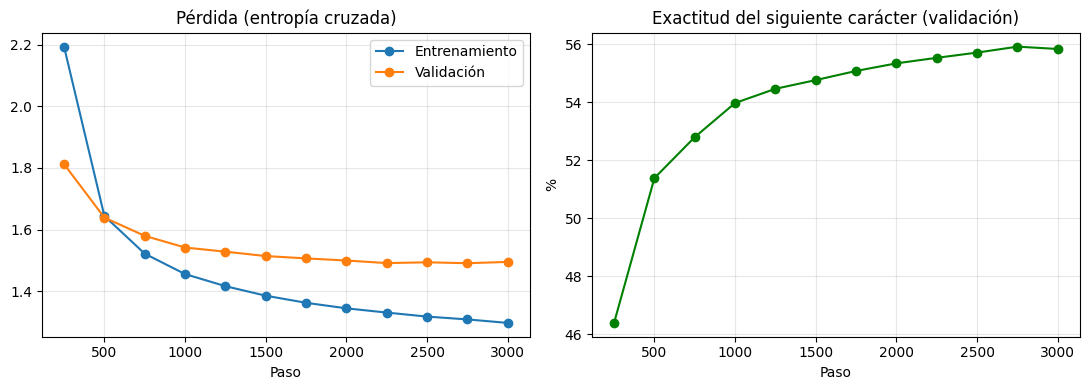



{'parametros': 946625, 'tiempo_entrenamiento_s': 120.4, 'perdida_val': 1.4981, 'perplejidad_val': 4.473, 'exactitud_siguiente_caracter': 55.76}


In [64]:
# Curvas de aprendizaje
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["step"], history["train_loss"], marker="o", label="Entrenamiento")
ax[0].plot(history["step"], history["val_loss"], marker="o", label="Validación")
ax[0].set_title("Pérdida (entropía cruzada)"); ax[0].set_xlabel("Paso"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(history["step"], [a * 100 for a in history["val_acc"]], marker="o", color="green")
ax[1].set_title("Exactitud del siguiente carácter (validación)"); ax[1].set_xlabel("Paso"); ax[1].set_ylabel("%"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("curvas_lstm.png", dpi=150); plt.show()

final_val_loss, final_val_acc = evaluate_lstm(n_batches=50)
RESULTS["lstm"] = {
    "parametros": lstm_params,
    "tiempo_entrenamiento_s": round(lstm_train_time, 1),
    "perdida_val": round(final_val_loss, 4),
    "perplejidad_val": round(math.exp(final_val_loss), 3),
    "exactitud_siguiente_caracter": round(final_val_acc * 100, 2),
}
print("\n")
print(RESULTS["lstm"])

Generación de texto y efecto de la temperatura

La temperatura controla la aleatoriedad del muestreo: 1) valores bajos de 0.5 dan texto conservador y repetitivo 2) valores altos de 1.2 a 1.5 dan texto mas creativo, pero con mas errores

Como aportacion propia, medimos la diversidad del texto generado con distinct-2 (proporcion de bigramas de palabras unicos)

Ahora voy a generar texto caracter por carcater a parti de un prompt.

temperature < 1: texto mas conservador y repetitivo

temperature > 1: texto mas variado, pero con mas errores.

In [65]:
@torch.no_grad()

def generate(model, prompt, n_chars=500, temperature=0.8):
    #1) Convertir el prompt a indices numericos (shape: 1 x largo_del_prompt)
    prompt_ids = torch.tensor([[stoi[ch] for ch in prompt]], device = device)

    #2) leer el prompt completo
    output, state = model(prompt_ids)

    #prediccion traer el ultimo caracter
    next_char_logits = output[:, -1, :]

    generated_chars = list(prompt)

    #3) generar un caracter a la vez
    for _ in range(n_chars):
        #convertir logits en probabilidades
        #la temperatura las suaviza o agudiza
        probs = torch.softmax(next_char_logits / temperature, dim = -1)

        #muestrear el siguiente caracter segun esas probabilidades
        next_id = torch.multinomial(probs, num_samples=1)
        generated_chars.append(itos[next_id.item()])

        #alimentar solo el nuevo caracter
        #el estado conserva el contexto previo
        output, state = model(next_id, state)
        next_char_logits = output[:, -1, :]

    return "".join(generated_chars)

Diversidad del texto: proporcion de bigramas de palabras unicos (0 o 1).

Valores cercanos a 1 = poco repetitivo
Cercanos a 0 = muy repetitivo

In [66]:
def distinct_2(text):
    words = text.split()
    bigrams = list(zip(words, words[1:]))
    unique_bigrams = set(bigrams)
    #max() evita dividir entre 0
    return len(unique_bigrams) / max(len(bigrams), 1)

In [67]:
#comparo temperaturas
PROMPT = "ROMEO:\n"
TEMPERATURES = [0.5, 0.8, 1.2]

#temperatura -> texto generado
lstm_samples = {}

for temperature in TEMPERATURES:

    #utilizo la misma semilla para que la comparacion sea justa
    torch.manual_seed(SEED)

    sample = generate(lstm_model, PROMPT, n_chars = 500, temperature=temperature)
    lstm_samples[temperature] = sample

    print(f"=== Temperatura {temperature} | distinct-2 = {distinct_2(sample):.3f} ===")
    print(sample, "\n")

=== Temperatura 0.5 | distinct-2 = 0.961 ===
ROMEO:
O me, you thought the guest of the state of speets.

Clown:
A mile and a curst to the state of the sea.

HENRY BOLINGBROKE:
Nay, sir, if thou hast pain them to my son;
But she was done the earth of a fandish men
Did be meditates of a hand,
And the hand, and be touching your mother be
dear.

First Servant:
Why shall I be a thing?

ROMEO:
A man of such a man. Here in his good
services; the officer than to me to express
That eye become the shame of our friendshill'd and
the countrymen and wretch in 

=== Temperatura 0.8 | distinct-2 = 1.000 ===
ROMEO:
O which, good saint, cousin, and pall I kill'd him need,
She comes them. For them as thou hast used
That and the down's friends Bont of him:
Murder this world dismest nothing.

CLAUDIO:
And serve that?

MENENIUS:
May he say, who comes another tapented?

MENENIUS:
Come, you be, sir, side and dreadful fack.

MONTAGUE:
He sense them to lime in Edward's blood
That cold smritce: too forgod to ou

In [68]:
#guardar las metricas de diversidad en el diccionario de resultados
RESULTS["lstm"]["distinct2_por_temperatura"] = {
    str(temperature): round(distinct_2(sample), 3)
    for temperature, sample in lstm_samples.items()
}

### Parte B: Transformer preentrenado (T5-small) para resumen con Hugging Face

Usamos CNN/DailyMail 3.0.0 que contiene articulos de noticias con resumenes escritos por humanos.

T5 es un modelo texto-a-texto: se indica la tarea con el prefijo "summarize: ". Los textos se tokenizan (SentencePiece) y se truncan a 512 tokens.

In [69]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
#se utiliza mas adelante para calcular metricas
import evaluate

#configuracion

#articulos de prueba para evaluar
N_EVAL = 100

#ejemplo para el ajuste fino corto
N_TRAIN = 2000

#maximo de tokens del articulo que recibe el modelo
MAX_IN = 512

#maximo de tokens del resumen que genera el modelo
MAX_OUT = 96

#cargar el dataset CNN/DailyMail

#cada ejemplo tiene un articulo ("article") y su resumen de referencia ("highlights")
ds = load_dataset("abisee/cnn_dailymail", "3.0.0")

#subconjunto de prueba: los primeros N_EVAL articulos
test_ds = ds["test"].select(range(N_EVAL))

#subconjunto de entrenamiento: N_TRAIN ejemplos al azar (SEED lo hace reproducible)
train_ds = ds["train"].shuffle(seed=SEED).select(range(N_TRAIN))

#revisar los datos

#tamaño de cada particion y columnas disponibles
print(ds)

primer_ejemplo = test_ds[0]
print("\nEjemplo de artículo (primeros 400 caracteres):\n", primer_ejemplo["article"][:400])
print("\nResumen de referencia:\n", primer_ejemplo["highlights"])

DatasetDict({
    train: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 287113
    })
    validation: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 13368
    })
    test: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 11490
    })
})

Ejemplo de artículo (primeros 400 caracteres):
 (CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the court is based. The Palestinians signed the ICC's founding Rome Statute in January, when they also acce

Resumen de referencia:
 Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June .
Israel and the United States opposed the move, which could open the door to war c

Cargué `google-t5/t5-small` que tiene 60 millones de parametros, arquitectura encoder-decoder, preentrenado en C4 con multiples tareas y resumen. Para la generación, usamos beam search con `max_new_tokens=80` y penalización de repetición de n-gramas.

In [70]:
#cargar el modelo y el tokenizador
MODEL_NAME = "google-t5/t5-small"

#tokenizador: convierte texto en numeros (tokens) y viceversa
#from_pretrained descarga de Hugging FAce el vocabulario con el que se entrenó T5.
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

#Modelo T5 con sus pesos ya preentrenados, enviado al GPU (o CPU)
#"Seq2SeqLM" = modelo que recibe una secuencia (articulo) y genera otra (resumen)
t5 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

#contar parametros: se suman los elementos de cada tensor de pesos del modelo
t5_params = 0
for parameter in t5.parameters():
    t5_params += parameter.numel()
print(f"Parámetros de T5-small: {t5_params:,}")

#metrica ROUGE: compara el resumen generado con el resumen humano de referencia
rouge = evaluate.load("rouge")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Parámetros de T5-small: 60,506,624


Función para generar resúmenes. Genera un resumen para cada articulo, procesandolos por lotes. Devuelve una lista de resumenes y tiempo total en segundos.

In [71]:
#solamente generamos texto, no entrenamos
#tampoco se calculan los gradientes
@torch.no_grad()
def summarize(model, articles, batch_size=8):

    #modo evaluacion (sin dropout)
    model.eval()
    summaries = []

    #como en el GPU las operaciones son asincronas,
    #se tiene que sincronizar para medir bien el tiempo
    if device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.time()

    #recorremos los articulos de 8 en 8
    for start in range(0, len(articles), batch_size):
        batch_articles = articles[start : start + batch_size]

        #T5 sabe que tarea hacer por el prefijo que lleva el texto
        batch_texts = []
        for article in batch_articles:
            batch_texts.append("summarize: " + article)

        #Texto -> numeros. Opciones:
        #max_length=MAX_IN : maximo de tokens por articulo
        #truncattion=True : permite ese corte
        #padding=True : rellena los mas cortos para que todos midan lo mismo
        #return_tensors="pt" : devuelve tensores de PyTorch
        encoded = tokenizer(
            batch_texts,
            max_length=MAX_IN,
            truncation=True,
            padding=True,
            return_tensors="pt"
        ).to(device)

        #Generar los resumenes (como numeros). Opciones:
        #num_beams=4 : beam search, explora 4 candidatos a la vez
        #max_new_tokens=80 : el resumen no pasa de 80 tokens
        #no_repeat_ngram_size=3 : prohibe repetir la misma secuencia de 3 tokens
        #early_stopping=True : termina cuando todos los candidatos estan completos
        generated_ids = model.generate(
            **encoded,
            num_beams=4,
            max_new_tokens=80,
            no_repeat_ngram_size=3,
            early_stopping=True,
        )

        #numeros -> texto legible (sin tokens especiales como <pad> o </s>)
        batch_summaries = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
        summaries += batch_summaries

    if device.type == "cuda":
        torch.cuda.synchronize()
    total_time = time.time() - start_time

    return summaries, total_time

Función para calcular ROUGE. Compara resumenes generados con los de referencia y devuelve ROUGE-1, 2 Y L (x100).

In [72]:
def rouge_scores(predictions, references):
    results = rouge.compute(predictions=predictions, references=references)

    scores = {}

    for metric in ["rouge1", "rouge2", "rougeL"]:
        scores[metric] = round(float(results[metric]) * 100, 2)
    return scores

Evaluación zero-shot (sin entrenamiento adicional)

Separa los articulos y resumenes de referencia.
test_ds es el conjunto de prueba (100 articulos). Cada fila tiene dos campos:
 - "article" -> el texto completo de la noticia
 - "highlights" -> el resumen escrito por humano (la "respuesta correcta")


In [73]:
articles = test_ds["article"]
refs = test_ds["highlights"]

Genera los resumenes con T5 sin entrenamiento adicional.
- summarize devuelve dos cosas: la lista de resúmenes y el tiempo que tardó.
- Python las recibe en dos variables a la vez (se llama "desempaquetar").



In [74]:
preds_zero, t_zero = summarize(t5, articles)

Medir la calidad comparando con los resúmenes humanos.

In [75]:
scores_zero = rouge_scores(preds_zero, refs)

Mostrar resultados

In [76]:
print("ROUGE zero-shot:", scores_zero)

seconds_per_article = t_zero / N_EVAL
print(f"Tiempo de inferencia ({N_EVAL} artículos): {t_zero:.1f} s  ->  {seconds_per_article:.2f} s por artículo")

ROUGE zero-shot: {'rouge1': 32.78, 'rouge2': 13.46, 'rougeL': 24.4}
Tiempo de inferencia (100 artículos): 18.0 s  ->  0.18 s por artículo


Fine-tuning

Para poder comparar el tiempo de entrenamiento con el de LSTM, ajustamos T5-small durante pocos pasos (1 época sobre `N_TRAIN` ejemplos). Esto ilustra la ventaja del *transfer learning*: partimos de pesos que ya "saben" lenguaje.

In [77]:
#configuracino de fine-tuning

#la cantidad de articulos procesados por paso
BATCH_FT = 8

#tasa de aprendizaje: 0.0003
LR_FT = 3e-4

Recibe un lote de ejemplos (articulos + resumenes humanos) y devuelve tres tensores listos para el modelo: ids de entrada, mascara y etiquetas.

In [78]:
#esta funcion convierte un lote de texto en numeros
def tokenize_batch(batch):
    #entrada: a cada articulo se le pone el prefijo "summarize: " y se convierte en tokens.
    #padding="max_length" rellena siempre hasta MAX_IN, para que todos los lotes midan igual.
    input_texts = []

    for article in batch["article"]:
        input_texts.append("summarize: " + article)

    inputs = tokenizer(
        input_texts,
        max_length=MAX_IN,
        truncation=True,
        padding="max_length",
        return_tensors="pt",
    )

    #salida esperada: los resumenes humanos (highlits) convertidos en tokens
    targets = tokenizer(
        batch["highlights"],
        max_length=MAX_OUT,
        truncation=True,
        padding="max_length",
        return_tensors="pt",
    )

    #las etiquetas son los ids de los resumenes.
    #Copiamos el tensor para no modificar el original.
    labels = targets["input_ids"].clone()

    #El relleno (<pad>) no es texto real, asi que no debe contar en la perdida.
    #PyTorch ignora automaticamente las posiciones con el valor -100.
    labels[labels == tokenizer.pad_token_id] = -100

    return inputs["input_ids"], inputs["attention_mask"], labels

Optimizador Adam con una forma mejorada de regularizacion (weight decay)

In [79]:
optimizer_ft = torch.optim.AdamW(t5.parameters(), lr=LR_FT)

#alias para conservar el nombre que usan otras celdas
opt_ft = optimizer_ft

Preparar el ciclo

In [80]:
#modo entrenamiento (dropout activo)
t5.train()

#aqui guardamos la perdida de cada paso para graficarla
ft_losses = []

if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.time()

Fine-tuning cycle: 1 epoca con ejemplos de cantidad N_TRAIN

In [81]:
for start in range(0, N_TRAIN, BATCH_FT):
    step = start // BATCH_FT

    #1) Tomar el siguiente lote de 8 ejemplos y convertirlo en numeros
    chunk = train_ds[start : start + BATCH_FT]
    input_ids, attention_mask, labels = tokenize_batch(chunk)

    #2) Mover los tensores al GPU o CPU
    input_ids = input_ids.to(device)
    attention_mask = attention_mask.to(device)
    labels = labels.to(device)

    #3) Forward pass: si le damos "labels", el modelo calcula solamente la perdida
    outputs = t5(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    loss = outputs.loss

    #4) Borrar gradientes anteriores, calcular los nuevos gradientes
    #y recortarlos
    optimizer_ft.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(t5.parameters(), 1.0)

    #5) Actualizar los pesos
    optimizer_ft.step()

    ft_losses.append(loss.item())

    # Mostar progreso cada 25 pasos
    if step % 25 == 0:
        print(f"paso {step:4d} | pérdida {loss.item():.3f}")

paso    0 | pérdida 2.476
paso   25 | pérdida 1.973
paso   50 | pérdida 2.102
paso   75 | pérdida 2.372
paso  100 | pérdida 2.035
paso  125 | pérdida 2.140
paso  150 | pérdida 1.832
paso  175 | pérdida 2.278
paso  200 | pérdida 1.587
paso  225 | pérdida 2.574


Medir el tiempo total

In [82]:
if device.type == "cuda":
    torch.cuda.synchronize()
t5_ft_time = time.time() - start_time
print(f"Tiempo de ajuste fino: {t5_ft_time:.1f} s")

Tiempo de ajuste fino: 99.3 s


Graficar la perdida

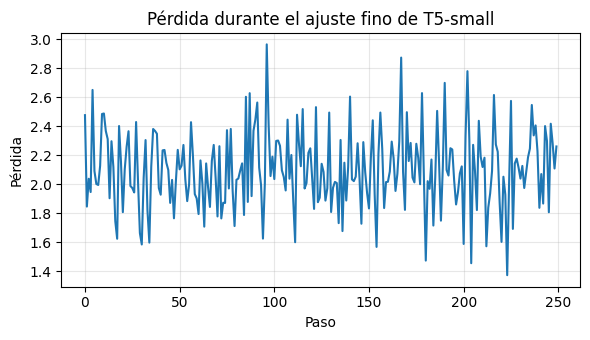

In [83]:
plt.figure(figsize=(6, 3.5))
plt.plot(ft_losses)
plt.title("Pérdida durante el ajuste fino de T5-small")
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("curva_t5_ft.png", dpi=150)
plt.show()

Generar resúmenes con el modelo ya ajustado. Es la misma función y los mismos 100 artículos que en zero-shot. Lo único distinto es que t5 ahora tiene los pesos actualizados por el fine-tuning.

In [84]:
preds_ft, t_ft = summarize(t5, articles)

Medir la calidad contra los resúmenes humanos

In [85]:
scores_ft = rouge_scores(preds_ft, refs)
print("ROUGE tras ajuste fino:", scores_ft)

ROUGE tras ajuste fino: {'rouge1': 32.14, 'rouge2': 13.22, 'rougeL': 23.97}


Guardar todos los resultados de T5 en un solo diccionario

In [86]:
#tiempo de inferencia por articulo
seconds_per_article = round(t_ft / N_EVAL, 3)

#tiempo del ajusto fino, 1 decimal
fine_tuning_time = round(t5_ft_time, 1)

RESULTS["t5"] = {
    "modelo": MODEL_NAME,                        # qué modelo usamos
    "parametros": t5_params,                     # cuántos parámetros tiene
    "n_eval": N_EVAL,                            # artículos usados para evaluar
    "n_train_ft": N_TRAIN,                       # ejemplos usados en el ajuste fino
    "rouge_zero_shot": scores_zero,              # ROUGE sin ajuste (celda anterior)
    "rouge_ajuste_fino": scores_ft,              # ROUGE con ajuste
    "tiempo_ajuste_fino_s": fine_tuning_time,    # segundos que duró el ajuste fino
    "inferencia_s_por_articulo": seconds_per_article,
}

In [87]:
for metric in ["rouge1", "rouge2", "rougeL"]:
    before = scores_zero[metric]
    after = scores_ft[metric]
    print(f"{metric}: {before} -> {after}  (cambio: {after - before:+.2f})")

rouge1: 32.78 -> 32.14  (cambio: -0.64)
rouge2: 13.46 -> 13.22  (cambio: -0.24)
rougeL: 24.4 -> 23.97  (cambio: -0.43)


Ejemplos generados (artículo, referencia, zero-shot y fine-tunning)

In [88]:
for i in range(3):
    print(f"--- Ejemplo {i+1} ---")
    print("ARTÍCULO (inicio):", articles[i][:300].replace("\n", " "), "...")
    print("REFERENCIA :", refs[i].replace("\n", " "))
    print("ZERO-SHOT  :", preds_zero[i])
    print("AJUSTE FINO:", preds_ft[i], "\n")

--- Ejemplo 1 ---
ARTÍCULO (inicio): (CNN)The Palestinian Authority officially became the 123rd member of the International Criminal Court on Wednesday, a step that gives the court jurisdiction over alleged crimes in Palestinian territories. The formal accession was marked with a ceremony at The Hague, in the Netherlands, where the cou ...
REFERENCIA : Membership gives the ICC jurisdiction over alleged crimes committed in Palestinian territories since last June . Israel and the United States opposed the move, which could open the door to war crimes investigations against Israelis .
ZERO-SHOT  : the palestinians signed the ICC's founding Rome Statute in January. it also accepted its jurisdiction over alleged crimes committed in the occupied territories. a preliminary examination into the situation in Palestinian territories was opened.
AJUSTE FINO: The Palestinian Authority officially becomes the 123rd member of the International Criminal Court. The court is based in The Hague, in the N

Gráfica de ROUGE: zero-shot vs fine-tuning

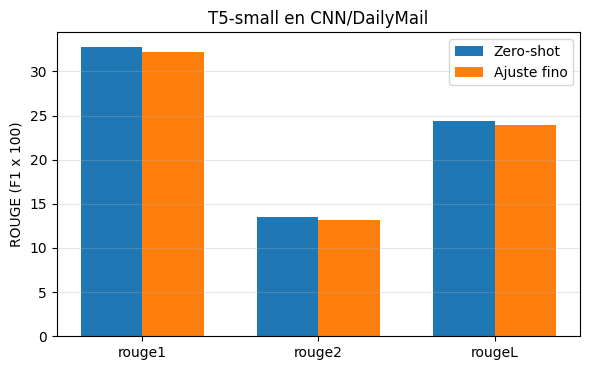

In [89]:
labels = ["rouge1", "rouge2", "rougeL"]
x = np.arange(len(labels)); w = 0.35
plt.figure(figsize=(6, 3.8))
plt.bar(x - w/2, [scores_zero[k] for k in labels], w, label="Zero-shot")
plt.bar(x + w/2, [scores_ft[k] for k in labels], w, label="Ajuste fino")
plt.xticks(x, labels); plt.ylabel("ROUGE (F1 x 100)"); plt.title("T5-small en CNN/DailyMail"); plt.legend(); plt.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("rouge_t5.png", dpi=150); plt.show()

### Parte C) Comparación entre ambos modelos

Las dos actividades son distintas, porque una es de generación libre y la otra es de resumen condicioando. Por ende, las métricas no son directamente comparables (exactitud de carácter/perplejidad vs. ROUGE). Por eso comparo dimensiones comunes: parámetros, tiempo, datos necesarios y calidad cualitativa de los ejemplos.

,Criterio,LSTM (desde cero),T5-small (preentrenado)
0,Tarea,Generación de texto (carácter),Resumen abstractivo
1,Dataset,Tiny Shakespeare,CNN/DailyMail
2,Parámetros,"946,625","60,506,624"
3,Entrenamiento,"Desde cero, 3000 pasos",Preentrenado + ajuste fino corto
4,Tiempo de entrenamiento (s),120.4,99.3
5,Métrica principal,Perplejidad 4.473 | exactitud 55.76 %,ROUGE-1 32.14 | ROUGE-L 23.97
6,Procesamiento de la secuencia,Secuencial (paso a paso),Paralelo (atención sobre toda la secuencia)


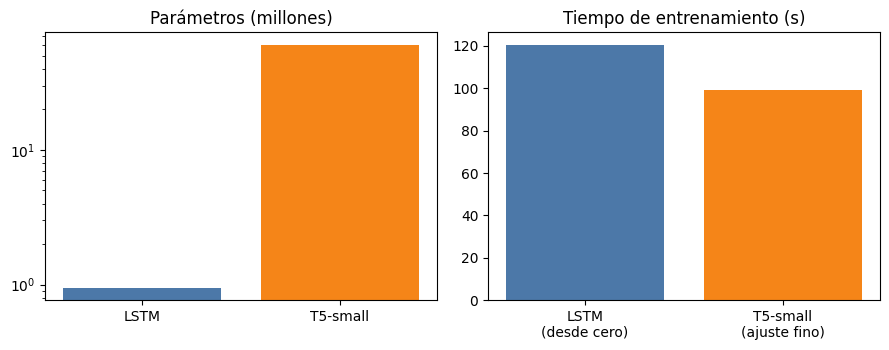

{
  "lstm": {
    "parametros": 946625,
    "tiempo_entrenamiento_s": 120.4,
    "perdida_val": 1.4981,
    "perplejidad_val": 4.473,
    "exactitud_siguiente_caracter": 55.76,
    "distinct2_por_temperatura": {
      "0.5": 0.961,
      "0.8": 1.0,
      "1.2": 1.0
    }
  },
  "t5": {
    "modelo": "google-t5/t5-small",
    "parametros": 60506624,
    "n_eval": 100,
    "n_train_ft": 2000,
    "rouge_zero_shot": {
      "rouge1": 32.78,
      "rouge2": 13.46,
      "rougeL": 24.4
    },
    "rouge_ajuste_fino": {
      "rouge1": 32.14,
      "rouge2": 13.22,
      "rougeL": 23.97
    },
    "tiempo_ajuste_fino_s": 99.3,
    "inferencia_s_por_articulo": 0.179
  }
}


In [90]:
comparison = pd.DataFrame({
    "Criterio": ["Tarea", "Dataset", "Parámetros", "Entrenamiento", "Tiempo de entrenamiento (s)",
                 "Métrica principal", "Procesamiento de la secuencia"],
    "LSTM (desde cero)": ["Generación de texto (carácter)", "Tiny Shakespeare", f"{lstm_params:,}", "Desde cero, 3000 pasos",
                          f"{RESULTS['lstm']['tiempo_entrenamiento_s']}",
                          f"Perplejidad {RESULTS['lstm']['perplejidad_val']} | exactitud {RESULTS['lstm']['exactitud_siguiente_caracter']} %",
                          "Secuencial (paso a paso)"],
    "T5-small (preentrenado)": ["Resumen abstractivo", "CNN/DailyMail", f"{t5_params:,}", "Preentrenado + ajuste fino corto",
                                f"{RESULTS['t5']['tiempo_ajuste_fino_s']}",
                                f"ROUGE-1 {scores_ft['rouge1']} | ROUGE-L {scores_ft['rougeL']}",
                                "Paralelo (atención sobre toda la secuencia)"],
})
display(comparison)

# Comparación visual de tamaño y tiempo
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].bar(["LSTM", "T5-small"], [lstm_params / 1e6, t5_params / 1e6], color=["#4C78A8", "#F58518"])
ax[0].set_title("Parámetros (millones)"); ax[0].set_yscale("log")
ax[1].bar(["LSTM\n(desde cero)", "T5-small\n(ajuste fino)"], [RESULTS["lstm"]["tiempo_entrenamiento_s"], RESULTS["t5"]["tiempo_ajuste_fino_s"]], color=["#4C78A8", "#F58518"])
ax[1].set_title("Tiempo de entrenamiento (s)")
plt.tight_layout(); plt.savefig("comparacion.png", dpi=150); plt.show()

with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2)
print(json.dumps(RESULTS, ensure_ascii=False, indent=2))